<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/pytorch/basics/Models_and_optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pytorch - torch.nn
- To customise and design the model architecture to suit our problem, pytorch has designed many modules. some of them are torch.nn, torch.optim, Dataset, DataLoader
- We'll build a simple linear classifier(logistic regression) for MNIST dataset without using these modules and then minimise our code with these modules.

### Classifier without torch.nn module.

In [1]:
from keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
# We'll use mnist dataset from keras
(train_X, train_y), (test_X, test_y) = mnist.load_data()

In [3]:
# Explore the dataset

print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)
print(type(train_X))


(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
<class 'numpy.ndarray'>


- we have 60,000 train images and 10,000 test images.
- The images are np.arrays with shape (28*28) - This is important as we have to flatten these images before passing them through our model.
- we also have to convert these numpy arrays to pytorch tensors.


The label for the first training image is:  5


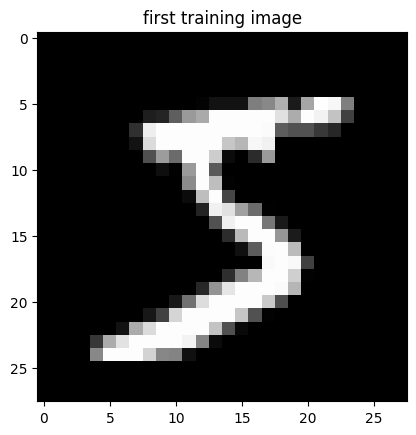

In [4]:
plt.imshow(train_X[0], cmap = 'gray')
plt.title('first training image')
print('The label for the first training image is: ',train_y[0])

In [5]:
train_X_tensor = torch.from_numpy(train_X.reshape(60000,784)).float()
train_y_tensor = torch.from_numpy(train_y).long()
test_X_tensor = torch.from_numpy(test_X.reshape(10000,784)).float()
test_y_tensor = torch.from_numpy(test_y).long()

In [6]:
print('tensor shapes are: ',train_X_tensor.shape, train_y_tensor.shape,test_X_tensor.shape,test_y_tensor.shape)
print(train_y_tensor.min(), train_y_tensor.max())

tensor shapes are:  torch.Size([60000, 784]) torch.Size([60000]) torch.Size([10000, 784]) torch.Size([10000])
tensor(0) tensor(9)


Text(0.5, 1.0, 'tensor of the first training image')

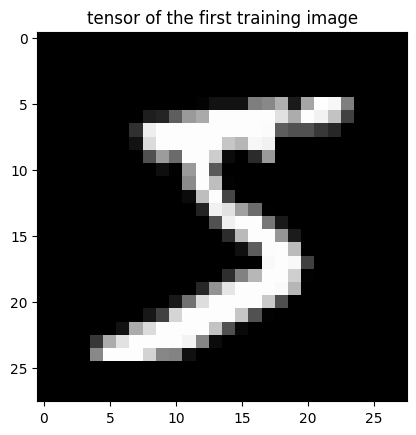

In [7]:
plt.imshow(train_X_tensor[0].reshape(28,28), cmap = 'gray')
plt.title('tensor of the first training image')

- Initilize weights, define loss function and optimizer

In [8]:
weights = torch.randn(10,784, requires_grad = True)   #weights of size (output * input)
#weights.requires_grad_()
bias = torch.zeros(10, requires_grad = True)

print('shape of the weights tensor:', weights.shape)
print('shape of the bias tensor:', bias.shape)

shape of the weights tensor: torch.Size([10, 784])
shape of the bias tensor: torch.Size([10])


In [9]:
# define our linear classification (model func), loss func

def log_softmax(x):
  """
  We use log_softmax function instead of sigmoid function as we are working with vectors not scalars (like in the last notebook)
  and log prevents the underflow of the exponential function.
  """
  #max val
  x_max = x.max(dim=-1, keepdim=True).values

  #softmax:
  #return (x-x_max).exp()/(x-x_max).exp().sum(dim = -1, keepdim = True)

  return (x - x_max) - (x - x_max).exp().sum(dim=-1, keepdim=True).log()

def l_model(xb):
  return log_softmax(xb @ weights.t() + bias)



In [10]:
# expample prediction:
pred = l_model(test_X_tensor[0:64])
print(pred[0], pred.shape)

tensor([-6065.1641, -2182.0249, -3942.0654, -4893.2119,   -50.1475, -6278.7729,
            0.0000, -3354.2603, -3651.9114, -5057.8281],
       grad_fn=<SelectBackward0>) torch.Size([64, 10])


In [11]:
#loss function
def loss_fn(preds, yb):
  # preds shape: (batch_size, 10)
  # yb shape: (batch_size,)

  batch_size = preds.shape[0]

  # 1. Create a clean 1D tensor of row indices [0, 1, 2, ..., batch_size-1]
  row_indices = torch.arange(batch_size)

  # 3. Index the batch of predictions to get the correct log-probabilities
  correct_log_preds = preds[row_indices, yb]

  # 4. Return negative mean log-likelihood
  return -correct_log_preds.mean()


def nll(input, target):
    return -input[range(target.shape[0]), target].mean()

#example loss
print('example loss is: ',nll(pred, test_y_tensor[0:64]))

example loss is:  tensor(2485.6448, grad_fn=<NegBackward0>)


In [12]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()

print(accuracy(pred,  test_y_tensor[0:64]))

tensor(0.1562)


- now let us put everythng in a loop

In [13]:
lr = 0.4
epochs = 50
bs = 64
n = len(train_X_tensor)

loss_log = []

for epoch in range(epochs):
  batch_losses = []
  print(f'training {epoch}')
  # Loop through all batches
  for i in range((n - 1) // bs + 1):
    start_i = i * bs
    end_i = start_i + bs

    xb = train_X_tensor[start_i:end_i]
    yb = train_y_tensor[start_i:end_i]

    preds = l_model(xb)

    loss = loss_fn(preds, yb)
    batch_losses.append(loss.item())

    loss.backward()

    with torch.no_grad():
      weights -= weights.grad * lr
      bias -= bias.grad *lr
      weights.grad.zero_()
      bias.grad.zero_()
  avg_epoch_loss = sum(batch_losses)/len(batch_losses)
  loss_log.append(avg_epoch_loss)

print('Inference on test images')
preds= l_model(test_X_tensor)
acc = accuracy(preds, test_y_tensor)
print('accuracy is: ',acc)

training 0
training 1
training 2
training 3
training 4
training 5
training 6
training 7
training 8
training 9
training 10
training 11
training 12
training 13
training 14
training 15
training 16
training 17
training 18
training 19
training 20
training 21
training 22
training 23
training 24
training 25
training 26
training 27
training 28
training 29
training 30
training 31
training 32
training 33
training 34
training 35
training 36
training 37
training 38
training 39
training 40
training 41
training 42
training 43
training 44
training 45
training 46
training 47
training 48
training 49
Inference on test images
accuracy is:  tensor(0.8748)


In [14]:
print(f'final loss after {epochs} epochs: ',loss_log[-1], len(loss_log))

final loss after 50 epochs:  5513.324398927343 50


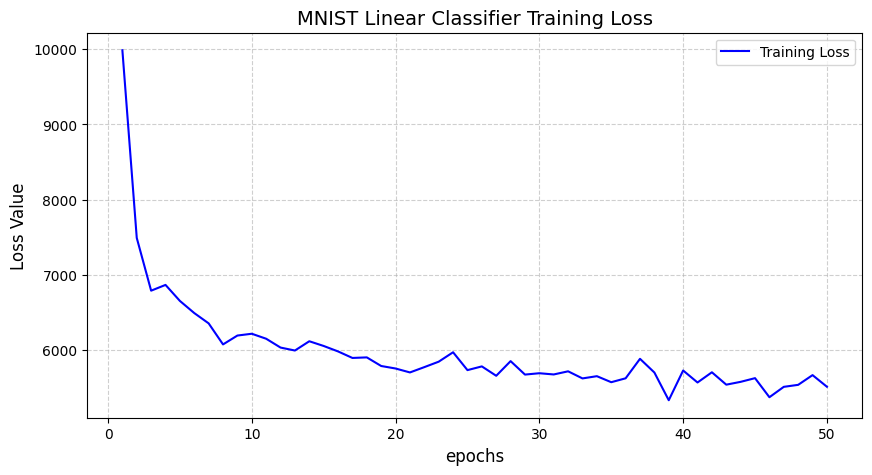

In [15]:
#arr = [x.item() for x in loss_log]
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1),loss_log, color="blue", linewidth=1.5, label="Training Loss")

# Add labels, title, and grid for readability
plt.title("MNIST Linear Classifier Training Loss", fontsize=14)
plt.xlabel("epochs", fontsize=12)
plt.ylabel("Loss Value", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Display the plot
plt.show()

- The training loss seems to fluctuate a lot and claearly is reducing over the epochs.
- we can minimize these fluctuations by increasing the batch size a little, but for this notebook, the goal is to see how pytorch.nn module can help our model building abilities.

### with torch.nn module

In [16]:
# we start by defining a class for uour model and import the nn.Module characteristics
from torch import nn

class logistic_reg(nn.Module):

  """
  Takes in input (xb) and returns 'xb @ weights.t() + bias'
  """
  def __init__(self, input_size, output_size):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(output_size,input_size))     #The nn.Parameters lets pytorch know that we intend to use these as parameters and enable autograd calculation with a ton of additional features
    self.bias = nn.Parameter(torch.zeros(output_size))

  def forward(self, xb):
    '''
    This is the starting point for pytorch
    '''
    return xb @ self.weights.t() + self.bias

### torch.nn.functional

In [17]:
# pytorch provides a lot of loss functions and optimisers inbuilt we can use in our model building

import torch.nn.functional as F

loss_fn = F.cross_entropy
# The cross entropy from pytorch requires raw logits from our model. It applies softmax on the raw logits
# which is why we have not applied any softmax in our 'logisic_reg' model.


In [18]:
xb = test_X_tensor[0:64]
yb = test_y_tensor[0:64]
logistic_model1 = logistic_reg(train_X_tensor.shape[-1], 10)

predictions = logistic_model1(xb)

loss = loss_fn(predictions, yb)
print(loss)

tensor(3060.1621, grad_fn=<NllLossBackward0>)


In [19]:
# we can now put everything in a function to train our model and update our weights just as before.
def fit():
    for epoch in range(epochs):
        for i in range((n - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = train_X_tensor[start_i:end_i]
            yb = train_y_tensor[start_i:end_i]
            pred = logistic_model1(xb)
            loss = loss_fn(pred, yb)

            loss.backward()
            with torch.no_grad():
              # we can use model.parameters() to update our parameters and model.zero_grad() to reset our gradients
                for p in logistic_model1.parameters():
                    p -= p.grad * lr
                logistic_model1.zero_grad()

fit()

### torch.optim

- But wait, we can even use optimization algorithms prebuilt for us. Instead of manually updating our parameters, we can do it with a single line.
  ```python
    opt.step()
    opt.zero_grad()
  ```


### nn.Linear
- pytorch also implemented basic models already configured, we can use `nn.Linear(input, output)` instead of defining it manually

In [20]:
class logistic_regression(nn.Module):

  '''
  the linear model internally initilizes weights and biases for us
  '''
  def __init__(self, input_size, output_size):
    super().__init__()
    self.linear = nn.Linear(input_size, output_size)

  def forward(self, xb):
    return self.linear(xb)

- we have our loss function from `torcn.nn.functional`
- we now can get our optimization algo from `torch.optim`

In [21]:
from torch import optim

logistic_model2 = logistic_regression(train_X_tensor.shape[-1],10)
optmizer = optim.SGD(logistic_model2.parameters(), lr = lr)

#test predictions
print(loss_fn(logistic_model2(xb), yb))

tensor(55.2270, grad_fn=<NllLossBackward0>)


In [22]:
# now let us put everything in a training loop.

loss_logger = []

for epoch in range(epochs):
  print(f'training {epoch}')
  for i in range((n - 1) // bs + 1):
    batch_loss_log = []
    start_i = i * bs
    end_i = start_i + bs
    xb = train_X_tensor[start_i:end_i]
    yb = train_y_tensor[start_i:end_i]
    pred = logistic_model2(xb)
    loss = loss_fn(pred, yb)
    batch_loss_log.append(loss.item())

    loss.backward()
    optmizer.step()  #automatic updates of our parameters
    optmizer.zero_grad()
  avg_batch_loss = sum(batch_loss_log)/len(batch_loss_log)
  loss_logger.append(avg_batch_loss)

training 0
training 1
training 2
training 3
training 4
training 5
training 6
training 7
training 8
training 9
training 10
training 11
training 12
training 13
training 14
training 15
training 16
training 17
training 18
training 19
training 20
training 21
training 22
training 23
training 24
training 25
training 26
training 27
training 28
training 29
training 30
training 31
training 32
training 33
training 34
training 35
training 36
training 37
training 38
training 39
training 40
training 41
training 42
training 43
training 44
training 45
training 46
training 47
training 48
training 49


In [ ]:
# detach everything from compute graph

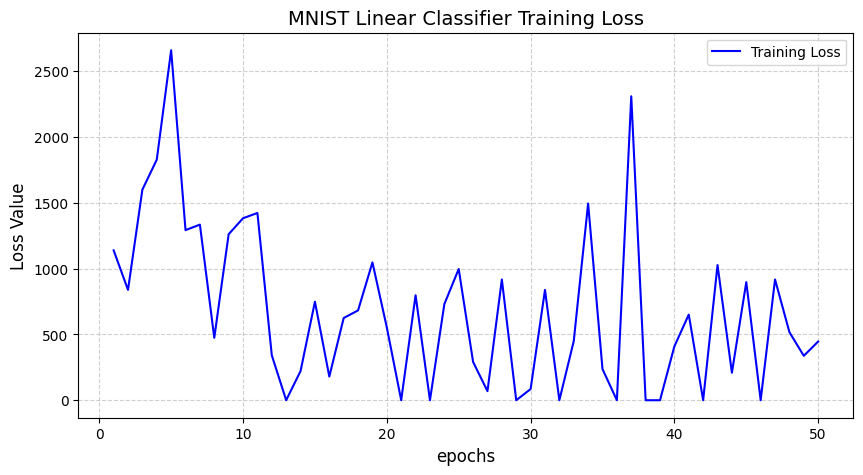

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1),loss_logger, color="blue", linewidth=1.5, label="Training Loss")

# Add labels, title, and grid for readability
plt.title("MNIST Linear Classifier Training Loss", fontsize=14)
plt.xlabel("epochs", fontsize=12)
plt.ylabel("Loss Value", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Display the plot
plt.show()

In [28]:
predictions2 = logistic_model2(test_X_tensor)
print(accuracy(predictions2, test_y_tensor)*100)

tensor(85.6900)


The predicted label for the first training image is:  7


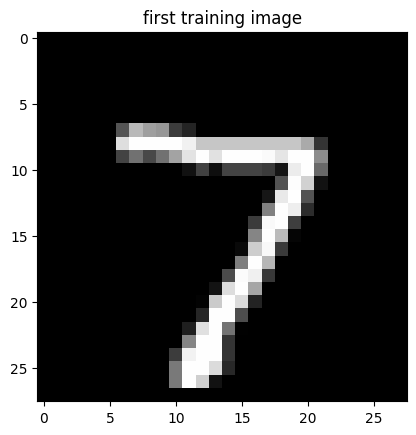

In [34]:
plt.imshow(test_X[0], cmap = 'gray')
plt.title('first training image')
print('The predicted label for the first training image is: ',torch.argmax(predictions2[0]).item())

### exploring the nn.linear layer


In [25]:
print('w:\n', logistic_model2)

w:
 logistic_regression(
  (linear): Linear(in_features=784, out_features=10, bias=True)
)


In [31]:
print(logistic_model2.linear.weight.shape)
print(logistic_model2.linear.bias.shape)

torch.Size([10, 784])
torch.Size([10])
